# How to access and extract post-2100 projections 

This notebook demonstrates how to extract daily time series of simulated temperature and precipitation for any location in North America, from 1950 to 2300. The data comes from the ESPO-G6-post2100 dataset, an ensemble of projections from global CMIP6 Earth System Models subsetted and bias-adjusted over North America using the Canadian Surface Reanalysis v3.2 as the reference dataset.

This notebook covers the following topics: 
1. list and classify datasets by scenario and model;
2. extract time series over a given location;
3. saving time series to disk;
4. compute the annual climatology;
5. make graphics of annual time series and climatologies.

By the end of the tutorial, you should be able to extract meteorological time series at any location from different climate model projections. 


## Accessing ESPO-G6-post2100 projections

The ESPO-G6-post2100 ensemble is hosted at [https://pavics.ouranos.ca/thredds](https://pavics.ouranos.ca/twitcher/ows/proxy/thredds/catalog/birdhouse/disk3/ouranos/ESPO-G/ESPO-G6-post2100_v1.0/catalog.html). The ensemble includes 17 simulations from eight Earth System Models and five greenhouse gases (GHG) concentration scenarios. Each file holds four years of daily data for one variable (minimum daily temperature, maximum daily temperature or daily total precipitation). The files are in the netCDF4 data format, a popular and efficient format for climate data, and hosted on a [THREDDS](https://www.unidata.ucar.edu/software/tds) server supporting different access mechanisms (direct downloads, streaming, metadata access, web mapping services, etc). 

Handling multiple files with 4-year chunks can be painful for time series spanning 1950 to 2300, so we created *aggregations* holding the entire time series for all variables. Compared to handling hundreds of files, this simplifies data access quite a bit. In the next cell, we'll use the [`siphon`](https://www.unidata.ucar.edu/software/siphon) library to open the THREDDS catalog, list the files in the ESPO-G6-post2100 directory, parse the file names and create a dictionary of links keyed by scenario and model. 

The aggregation names follow the pattern below, so we'll split the elements separated by underscores d retrieve the model and scenario: 

``<freq>_ESPO-G6-post2100_<version>_<era>_<activity>_<domain>-<reference>_<model>_<scenario>_<member>_<start>-<end>.ncml``

Note that if you ever need to access the original netCDF files in 4-year chunks, they are stored at the following link:
<https://pavics.ouranos.ca/twitcher/ows/proxy/thredds/catalog/birdhouse/disk3/ouranos/ESPO-G/ESPO-G6-post2100_v1.0/catalog.html>

In [1]:
import yaml
from siphon.catalog import TDSCatalog
from collections import defaultdict
from matplotlib import pyplot as plt

# Link to the aggregations - one per model and scenario
url = "https://pavics.ouranos.ca/twitcher/ows/proxy/thredds/catalog/datasets/simulations/bias_adjusted/cmip6/ouranos/ESPO-G/ESPO-G6-post2100v1.0/catalog.xml"

# Create catalog
cat = TDSCatalog(url)

# Parse file names and fill dictionary by scenario and model
def parse_name(s: str) -> (str, str):
    """Return the scenario and model names"""
    parts = s.split("_")
    return parts[8], parts[7]

# Store the names and datasets in dictionaries keyed by scenario and model
names = defaultdict(dict)
datasets = defaultdict(dict)
for name, ds in cat.datasets.items():
    scen, model = parse_name(name)
    names[scen][model] = name
    datasets[scen][model] = ds

# Pretty print the dataset names per scenario and model
print(yaml.dump(dict(names)))

ssp126:
  ACCESS-ESM1-5: day_ESPO-G6-post2100_v1.0_CMIP6_ScenarioMIP_NAM-C3_CSIRO_ACCESS-ESM1-5_ssp126_r1i1p1f1_1950-2300.ncml
  CanESM5: day_ESPO-G6-post2100_v1.0_CMIP6_ScenarioMIP_NAM-C3_CCCma_CanESM5_ssp126_r1i1p1f1_1950-2300.ncml
  EC-Earth3-Veg: day_ESPO-G6-post2100_v1.0_CMIP6_ScenarioMIP_NAM-C3_EC-Earth-Consortium_EC-Earth3-Veg_ssp126_r1i1p1f1_1950-2300.ncml
  MRI-ESM2-0: day_ESPO-G6-post2100_v1.0_CMIP6_ScenarioMIP_NAM-C3_MRI_MRI-ESM2-0_ssp126_r1i1p1f1_1950-2300.ncml
  UKESM1-0-LL: day_ESPO-G6-post2100_v1.0_CMIP6_ScenarioMIP_NAM-C3_MOHC_UKESM1-0-LL_ssp126_r4i1p1f2_1950-2300.ncml
ssp245:
  EC-Earth3-Veg: day_ESPO-G6-post2100_v1.0_CMIP6_ScenarioMIP_NAM-C3_EC-Earth-Consortium_EC-Earth3-Veg_ssp245_r1i1p1f1_1950-2300.ncml
ssp370:
  EC-Earth3-Veg: day_ESPO-G6-post2100_v1.0_CMIP6_ScenarioMIP_NAM-C3_EC-Earth-Consortium_EC-Earth3-Veg_ssp370_r1i1p1f1_1950-2300.ncml
ssp534-over:
  CNRM-ESM2-1: day_ESPO-G6-post2100_v1.0_CMIP6_ScenarioMIP_NAM-C3_CNRM-CERFACS_CNRM-ESM2-1_ssp534-over_r1i1p1f2_1

## Extracting time series at a given location

Each individual dataset includes minimum daily temperature (`tasmin`), maximum daily temperature (`tasmax`) and daily total precipitation (`pr`). The other time series, `dtr` is the daily temperature range and should correspond to `tasmax - tasmin`. The dataset also includes ground height (`orog`), the land-sea mask (`sftlf`) and other land area fractions. 

We open the OPeNDAP link using [`xarray`](https://docs.xarray.dev/en/stable/), a library faciliting the handling of multi-dimensional data. What you see in the next cell is the representation of the xarray dataset, with its dimensions (time, rlat, rlon), coordinates and data variables. We'll instruct xarray to use *chunks* when accessing the data. With such large datasets, this is necessary to avoid sending the server extremely large data requests. See this [tutorial](https://pavics-sdi.readthedocs.io/en/latest/notebooks/FAQ_dask_parallel.html) for more explanations on chunking. Note that we access the dataset through a streaming protocol called [OPeNDAP](https://www.opendap.org/) which lets us download only the data chunks needed for the analysis. 

Note also that we need to use a special datetime *coder*, because the time series goes beyond year 2262, the future bound of normal `datetime` objects. 

In [2]:
import xarray as xr

# Special instruction needed to handle time series extending beyond year 2262.
time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)

# Get the opendap link of one dataset
scen = "ssp245"
model = "EC-Earth3-Veg"
link = datasets[scen][model].access_urls["OPEnDAP"]

# Open remote dataset, including time coder options and chunk sizes
ds = xr.open_dataset(link, decode_times=time_coder, chunks={"time": 366*10, "rlon": 50, "rlat": 50})
ds

<xarray.Dataset> Size: 1TB
Dimensions:       (time: 128115, rlat: 758, rlon: 700)
Coordinates:
  * time          (time) object 1MB 1950-01-01 00:00:00 ... 2300-12-31 00:00:00
  * rlat          (rlat) float32 3kB -42.3 -42.21 -42.12 ... 25.65 25.74 25.83
  * rlon          (rlon) float32 3kB -34.95 -34.86 -34.77 ... 27.78 27.87 27.96
    rotated_pole  int32 4B ...
    lat           (rlat, rlon) float32 2MB dask.array<chunksize=(50, 50), meta=np.ndarray>
    lon           (rlat, rlon) float32 2MB dask.array<chunksize=(50, 50), meta=np.ndarray>
Data variables:
    tasmin        (time, rlat, rlon) float32 272GB dask.array<chunksize=(3660, 50, 50), meta=np.ndarray>
    tasmax        (time, rlat, rlon) float32 272GB dask.array<chunksize=(3660, 50, 50), meta=np.ndarray>
    pr            (time, rlat, rlon) float32 272GB dask.array<chunksize=(3660, 50, 50), meta=np.ndarray>
    dtr           (time, rlat, rlon) float32 272GB dask.array<chunksize=(3660, 50, 50), meta=np.ndarray>
    orog          (rlat, rlon) float32 2MB dask.array<chunksize=(50, 50), meta=np.ndarray>
    sftgif        (rlat, rlon) float32 2MB dask.array<chunksize=(50, 50), meta=np.ndarray>
    sftlf         (rlat, rlon) float32 2MB dask.array<chunksize=(50, 50), meta=np.ndarray>
    sftlkf        (rlat, rlon) float32 2MB dask.array<chunksize=(50, 50), meta=np.ndarray>
    sftof         (rlat, rlon) float32 2MB dask.array<chunksize=(50, 50), meta=np.ndarray>
Attributes: (12/51)
    Notes:                           Regridded on the grid of CaSR v3.2, then...
    avertissement:                   Ouranos ne donne aucune garantie, expres...
    code:                            https://github.com/Ouranosinc/ESPO-G/tre...
    contact:                         lavoie.juliette@ouranos.ca
    disclaimer:                      Ouranos make no warranty, either express...
    history:                         [2025-12-10 17:43:32] regridded with arg...
    ...                              ...
    bias_adjust_reference:           Canadian Surface Reanalysis (CaSR) v3.2
    bias_adjust_reference_citation:  https://doi.org/10.5194/hess-25-4917-2021
    terms_of_use:                    In addition to the provided licence, the...
    attribution:                     Use of this dataset should be acknowledg...
    modeling_realm:                  atmos
    source_institution:              EC-Earth-Consortium

The `rlat` and `rlon` coordinates of the dataset stand for *rotated pole coordinates*. These are the model coordinates, and do not correspond to real world latitudes and longitudes. The actual coordinates are stored in the `lat` and `lon` coordinates. To extract data for a given location, we first need to map real-world coordinates to model coordinates, and then use xarray's indexing capabilities (`sel`) to subset the data. 

In [3]:
from cartopy import crs as ccrs

# Coordinates of interest
lat = 50
lon = -77

# Model projection (rotated pole)
rot = ccrs.RotatedPole(
            pole_longitude=ds.rotated_pole.grid_north_pole_longitude,
            pole_latitude=ds.rotated_pole.grid_north_pole_latitude,
        )

# Rectangular lat, lon projection
pc = ccrs.PlateCarree()

# Convert coordinates to rotated pole coordinates
rlon, rlat = rot.transform_point(lon, lat, pc)

# Extract the coordinates of interest
sub = ds.sel(rlon=rlon, rlat=rlat, method="nearest")
sub

<xarray.Dataset> Size: 3MB
Dimensions:       (time: 128115)
Coordinates:
  * time          (time) object 1MB 1950-01-01 00:00:00 ... 2300-12-31 00:00:00
    rlat          float32 4B -7.11
    rlon          float32 4B 9.873
    rotated_pole  int32 4B ...
    lat           float32 4B dask.array<chunksize=(), meta=np.ndarray>
    lon           float32 4B dask.array<chunksize=(), meta=np.ndarray>
Data variables:
    tasmin        (time) float32 512kB dask.array<chunksize=(3660,), meta=np.ndarray>
    tasmax        (time) float32 512kB dask.array<chunksize=(3660,), meta=np.ndarray>
    pr            (time) float32 512kB dask.array<chunksize=(3660,), meta=np.ndarray>
    dtr           (time) float32 512kB dask.array<chunksize=(3660,), meta=np.ndarray>
    orog          float32 4B dask.array<chunksize=(), meta=np.ndarray>
    sftgif        float32 4B dask.array<chunksize=(), meta=np.ndarray>
    sftlf         float32 4B dask.array<chunksize=(), meta=np.ndarray>
    sftlkf        float32 4B dask.array<chunksize=(), meta=np.ndarray>
    sftof         float32 4B dask.array<chunksize=(), meta=np.ndarray>
Attributes: (12/51)
    Notes:                           Regridded on the grid of CaSR v3.2, then...
    avertissement:                   Ouranos ne donne aucune garantie, expres...
    code:                            https://github.com/Ouranosinc/ESPO-G/tre...
    contact:                         lavoie.juliette@ouranos.ca
    disclaimer:                      Ouranos make no warranty, either express...
    history:                         [2025-12-10 17:43:32] regridded with arg...
    ...                              ...
    bias_adjust_reference:           Canadian Surface Reanalysis (CaSR) v3.2
    bias_adjust_reference_citation:  https://doi.org/10.5194/hess-25-4917-2021
    terms_of_use:                    In addition to the provided licence, the...
    attribution:                     Use of this dataset should be acknowledg...
    modeling_realm:                  atmos
    source_institution:              EC-Earth-Consortium

Another way to subset the data is to use the [`clisops`](https://clisops.readthedocs.io/en/latest/) library and its [`subset_gridpoint`](https://clisops.readthedocs.io/en/latest/api.html#clisops.core.subset.subset_gridpoint) function.

```python
from clisops.core.subset import subset_gridpoint
sub = subset_gridpoint(ds, lat=lat, lon=lon)
```

The `clisops` library has a few other useful subsetting and averaging operations available, including one for the computation of [spatial averages](https://clisops.readthedocs.io/en/latest/api.html#clisops.core.average.average_shape) over a user-defined polygon, for example a shapefile from a Geographical Information System. 

If you want to apply a spatial rolling average, for example on a 3x3 grid, first call ``ds = ds.rolling(rlat=3, rlon=3, center=True).mean()`` before selecting coordinates. Because `xarray` uses [*lazy evaluation*](https://docs.xarray.dev/en/latest/user-guide/terminology.html#term-lazy), this won't launch a long computation, only record the operation. The rolling operation will only be executed on the data subset requested.


## Saving data subsets to disk

Once your subset is defined, it's useful to save it to disk. Further analyses run faster because there is no interaction with the server. To save the data subset in the original netCDF4 format, simply use 

```python
sub.to_netcdf(f"subset_{scen}_{model}.nc")
```

To write files in other formats, one strategy is to convert `xarray.Dataset` objects into `pandas.Dataframe` objects, which come with a large collection of export options, see <https://pandas.pydata.org/pandas-docs/stable/user_guide/io.html>. 

```python
df = sub.to_pandas()
df.to_excel("subset.xlsx", sheet_name=f"{scen} {model}")
```

Because streaming and saving the data takes a few minutes, now we'll just load the data saved previously. To show that we actually got the data, we'll plot a time series of annual mean maximum daily temperature and daily total precipitation.  

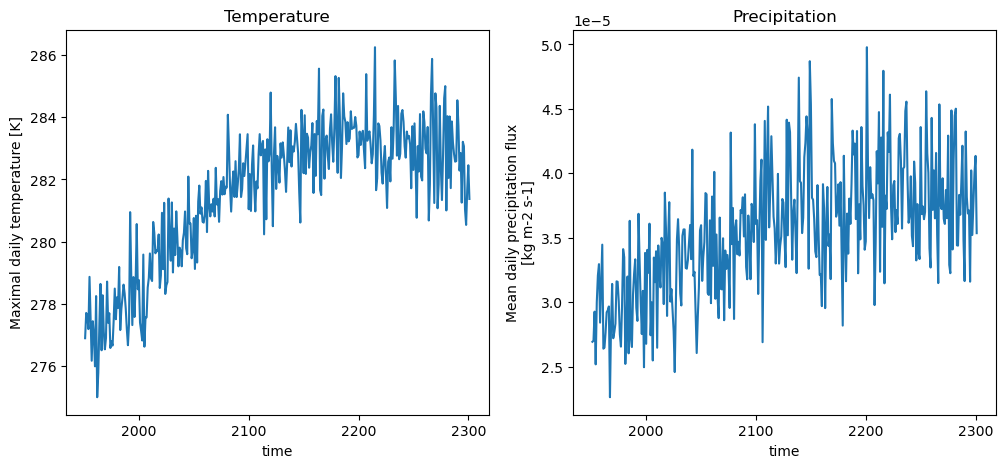

In [4]:
# Save file to disk - this takes a few minutes
# sub.to_netcdf(f"subset_{scen}_{model}.nc")

# Read file from disk
sub = xr.open_dataset(f"subset_{scen}_{model}.nc", decode_times=time_coder)

# Graph the annual mean of the maximum temperature and precipitation 
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Use `resample` to compute the yearly (YE) mean
sub.tasmax.resample(time="YE").mean().plot(ax=ax1)
sub.pr.resample(time="YE").mean().plot(ax=ax2)

ax1.set_title("Temperature")
ax2.set_title("Precipitation");

If you wonder why temperatures and in Kelvin and precipitation in kg/m²/s, it's because the dataset adheres to the [Climate and Forecast conventions](https://cfconventions.org/). The convention codifies community standards that facilitate the usage and comparison of datasets from different publishers.

## Compute climatologies

Now that we have extracted the data at the location of interest, we're ready to run a simple climatological analysis. We'll plot the annual temperature and precipitation cycles for two 30-year periods.

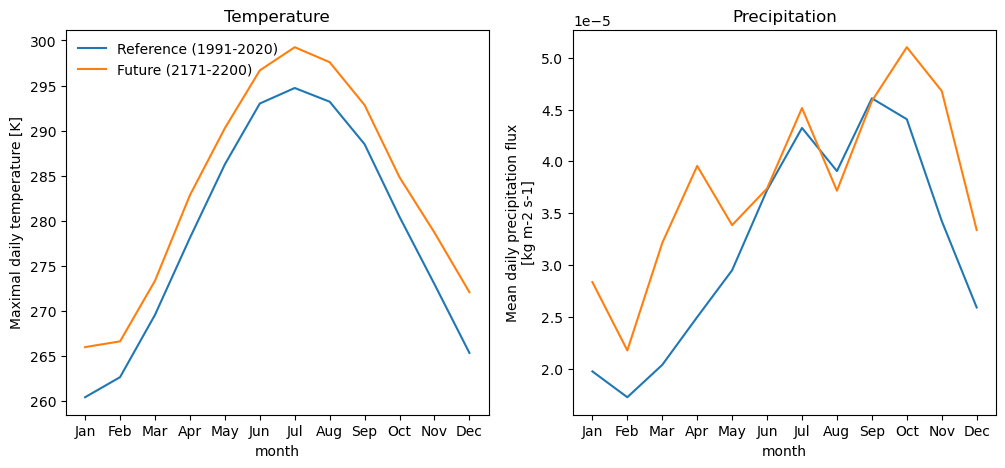

In [5]:
import calendar

# Select a 30 year period, group data by month and compute the mean
ref = sub.sel(time=slice("1991", "2020")).groupby("time.month").mean()
fut = sub.sel(time=slice("2171", "2200")).groupby("time.month").mean()

# Graphic
fig, (ax1, ax2) = plt.subplots(1, 2, sharex=True, figsize=(12,5))

# Temperature
ref.tasmax.plot(ax=ax1, label="Reference (1991-2020)")
fut.tasmax.plot(ax=ax1, label="Future (2171-2200)")
ax1.set_title("Temperature")

# Precipitation
ref.pr.plot(ax=ax2, label="Reference (1991-2020)")
fut.pr.plot(ax=ax2, label="Future (2171-2200)")
ax2.set_title("Precipitation")

# Show the months on the x-axis
ax2.set_xticks(range(1,13))
months = list(calendar.month_abbr)[1:]
ax2.set_xticklabels(months)
ax1.legend(loc="upper left", frameon=False);

A natural next step would be to run similar analyses for other scenarios and models to get a sense of the uncertainty. Our suggestion would be to first save to disk the different subsets, then aggregate them into a single `xarray.Dataset` along new `scen` and `model` dimensions. This makes it really easy to compute statistics across scenarios and reduces file handling. If you have any questions or issues related to data access, please email us at <pavics@ouranos.ca>.